In [2]:
%pip install kagglehub torch torchvision numpy matplotlib scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import random
import time
import json
import copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    f1_score
)

SEED = 42
BATCH_SIZE = 64
EPOCHS = 20
NUM_CLASSES = 33
IMAGE_SIZE = (32, 32)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Version TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU"))

# Télécharger la base de données
path = kagglehub.dataset_download(
    "benaddym/amazigh-handwritten-character-database-amhcd"
)

DATA_PATH = Path(path)

print("Dataset téléchargé dans :", DATA_PATH)
for item in DATA_PATH.iterdir():
    print(item.name, "->", "Dossier" if item.is_dir() else "Fichier")

c:\Users\admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Version TensorFlow : 2.22.0-rc0
GPU disponible : []
Download already complete (71167889 bytes).
Extracting files...
Dataset téléchargé dans : C:\Users\admin\.cache\kagglehub\datasets\benaddym\amazigh-handwritten-character-database-amhcd\versions\1
AMHCD_64 -> Dossier
labels -> Dossier


In [4]:
EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_files = [
    p for p in DATA_PATH.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTENSIONS
]

print("Nombre total d'images :", len(image_files))
print("\nPremiers fichiers trouvés :")

for p in image_files[:30]:
    print(p.relative_to(DATA_PATH))

Nombre total d'images : 25740

Premiers fichiers trouvés :
AMHCD_64\AMHCD_64\ya\ya_1.jpeg
AMHCD_64\AMHCD_64\ya\ya_10.jpeg
AMHCD_64\AMHCD_64\ya\ya_100.jpeg
AMHCD_64\AMHCD_64\ya\ya_101.jpeg
AMHCD_64\AMHCD_64\ya\ya_102.jpeg
AMHCD_64\AMHCD_64\ya\ya_103.jpeg
AMHCD_64\AMHCD_64\ya\ya_104.jpeg
AMHCD_64\AMHCD_64\ya\ya_105.jpeg
AMHCD_64\AMHCD_64\ya\ya_106.jpeg
AMHCD_64\AMHCD_64\ya\ya_107.jpeg
AMHCD_64\AMHCD_64\ya\ya_108.jpeg
AMHCD_64\AMHCD_64\ya\ya_109.jpeg
AMHCD_64\AMHCD_64\ya\ya_11.jpeg
AMHCD_64\AMHCD_64\ya\ya_110.jpeg
AMHCD_64\AMHCD_64\ya\ya_111.jpeg
AMHCD_64\AMHCD_64\ya\ya_112.jpeg
AMHCD_64\AMHCD_64\ya\ya_113.jpeg
AMHCD_64\AMHCD_64\ya\ya_114.jpeg
AMHCD_64\AMHCD_64\ya\ya_115.jpeg
AMHCD_64\AMHCD_64\ya\ya_116.jpeg
AMHCD_64\AMHCD_64\ya\ya_117.jpeg
AMHCD_64\AMHCD_64\ya\ya_118.jpeg
AMHCD_64\AMHCD_64\ya\ya_119.jpeg
AMHCD_64\AMHCD_64\ya\ya_12.jpeg
AMHCD_64\AMHCD_64\ya\ya_120.jpeg
AMHCD_64\AMHCD_64\ya\ya_121.jpeg
AMHCD_64\AMHCD_64\ya\ya_122.jpeg
AMHCD_64\AMHCD_64\ya\ya_123.jpeg
AMHCD_64\AMHCD_64\ya\y

In [5]:
def contains_images(folder):
    if not folder.is_dir():
        return False

    return any(
        f.is_file() and f.suffix.lower() in EXTENSIONS
        for f in folder.rglob("*")
    )


def has_class_folders(folder):
    if not folder.is_dir():
        return False

    class_dirs = [d for d in folder.iterdir() if d.is_dir()]

    valid_dirs = [
        d for d in class_dirs
        if contains_images(d)
    ]

    return len(valid_dirs) >= 2


# Chercher un dossier nommé train ou training
train_candidates = [
    p for p in DATA_PATH.rglob("*")
    if p.is_dir()
    and p.name.lower() in {"train", "training"}
    and has_class_folders(p)
]

# Chercher un dossier nommé test ou testing
test_candidates = [
    p for p in DATA_PATH.rglob("*")
    if p.is_dir()
    and p.name.lower() in {"test", "testing"}
    and has_class_folders(p)
]

val_candidates = [
    p for p in DATA_PATH.rglob("*")
    if p.is_dir()
    and p.name.lower() in {"val", "valid", "validation"}
    and has_class_folders(p)
]


def get_class_names(folder):
    return sorted([
        d.name for d in folder.iterdir()
        if d.is_dir() and contains_images(d)
    ])


def collect_images(class_root, class_names):
    paths = []
    labels = []

    class_to_index = {
        name: i for i, name in enumerate(class_names)
    }

    for class_name in class_names:
        class_dir = class_root / class_name

        if not class_dir.exists():
            raise ValueError(
                f"Classe manquante : {class_name} dans {class_root}"
            )

        for p in class_dir.rglob("*"):
            if p.is_file() and p.suffix.lower() in EXTENSIONS:
                paths.append(str(p))
                labels.append(class_to_index[class_name])

    return np.array(paths), np.array(labels, dtype=np.int32)


# Variables finales
train_paths = val_paths = test_paths = None
y_train = y_val = y_test = None

if train_candidates:
    # Choisir le dossier train le plus proche de la racine téléchargée
    train_root = min(train_candidates, key=lambda p: len(p.parts))
    parent = train_root.parent

    test_root = next(
        (
            p for p in test_candidates
            if p.parent == parent
        ),
        None
    )

    val_root = next(
        (
            p for p in val_candidates
            if p.parent == parent
        ),
        None
    )

    class_names = get_class_names(train_root)

    train_paths, y_train = collect_images(train_root, class_names)

    if test_root is not None:
        test_names = get_class_names(test_root)
        if test_names != class_names:
            raise ValueError(
                "Les classes de train et test ne correspondent pas."
            )
        test_paths, y_test = collect_images(test_root, class_names)
    else:
        raise FileNotFoundError(
            "Un dossier train existe, mais aucun dossier test "
            "correspondant n'a été trouvé."
        )

    if val_root is not None:
        if get_class_names(val_root) != class_names:
            raise ValueError(
                "Les classes de train et validation ne correspondent pas."
            )
        val_paths, y_val = collect_images(val_root, class_names)
    else:
        # Créer validation à partir de train uniquement.
        train_paths, val_paths, y_train, y_val = train_test_split(
            train_paths,
            y_train,
            test_size=0.15,
            random_state=SEED,
            stratify=y_train
        )

else:
    # Cas où les dossiers des classes sont directement présents
    # sous un dossier racine.
    roots = [
        p for p in [DATA_PATH] + list(DATA_PATH.rglob("*"))
        if p.is_dir()
        and p.name.lower() not in {
            "train", "training", "test", "testing",
            "val", "valid", "validation"
        }
        and has_class_folders(p)
    ]

    if not roots:
        raise FileNotFoundError(
            "Impossible de détecter le dossier des classes. "
            "Consultez la cellule 3 pour identifier la structure."
        )

    # Privilégier le dossier qui contient le plus de classes
    class_root = max(
        roots,
        key=lambda p: len(get_class_names(p))
    )

    class_names = get_class_names(class_root)
    all_paths, all_labels = collect_images(class_root, class_names)

    train_paths, temp_paths, y_train, y_temp = train_test_split(
        all_paths,
        all_labels,
        test_size=0.30,
        random_state=SEED,
        stratify=all_labels
    )

    val_paths, test_paths, y_val, y_test = train_test_split(
        temp_paths,
        y_temp,
        test_size=0.50,
        random_state=SEED,
        stratify=y_temp
    )


if len(class_names) != NUM_CLASSES:
    raise ValueError(
        f"Le TP demande {NUM_CLASSES} classes, mais "
        f"{len(class_names)} ont été détectées : {class_names}"
    )

print("Classes :", class_names)
print("Nombre de classes :", len(class_names))
print("Images entraînement :", len(train_paths))
print("Images validation :", len(val_paths))
print("Images test :", len(test_paths))

Classes : ['ya', 'yab', 'yach', 'yad', 'yadd', 'yae', 'yaf', 'yag', 'yagh', 'yagw', 'yah', 'yahh', 'yaj', 'yak', 'yakw', 'yal', 'yam', 'yan', 'yaq', 'yar', 'yarr', 'yas', 'yass', 'yat', 'yatt', 'yaw', 'yax', 'yay', 'yaz', 'yazz', 'yey', 'yi', 'yu']
Nombre de classes : 33
Images entraînement : 18018
Images validation : 3861
Images test : 3861


In [6]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )

    image.set_shape([None, None, 1])

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.int32)

    return image, label


def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_dataset(train_paths, y_train, training=True)
val_ds = make_dataset(val_paths, y_val)
test_ds = make_dataset(test_paths, y_test)

print("Jeux de données TensorFlow créés.")

Jeux de données TensorFlow créés.


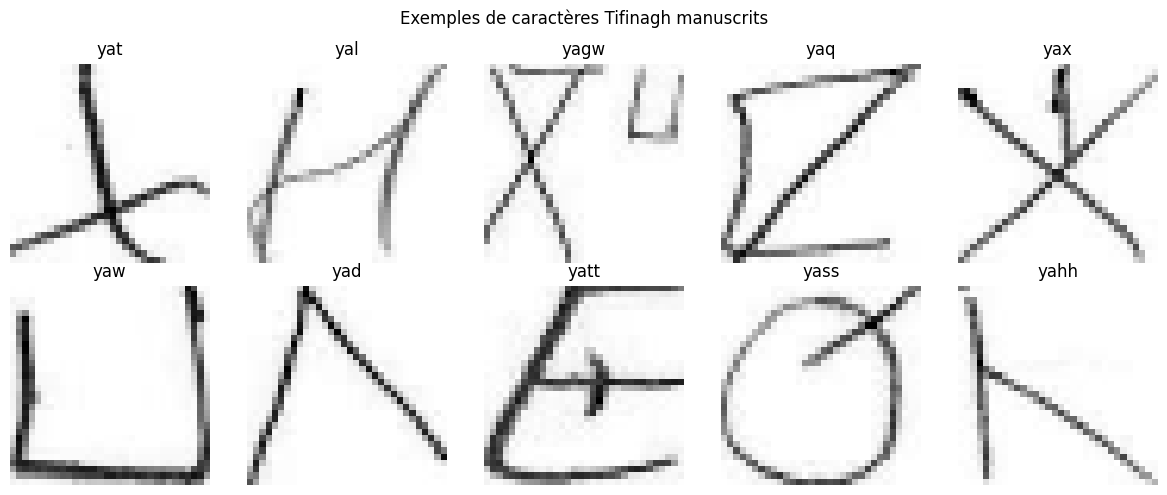

In [7]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 5))

for i in range(min(10, len(images))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].numpy().squeeze(), cmap="gray")
    plt.title(class_names[int(labels[i].numpy())])
    plt.axis("off")

plt.suptitle("Exemples de caractères Tifinagh manuscrits")
plt.tight_layout()
plt.show()

In [9]:
from tensorflow.keras import layers, models


def get_activation(name):
    name = name.lower()

    if name == "tanh":
        return layers.Activation("tanh")
    elif name == "relu":
        return layers.Activation("relu")
    elif name == "sigmoid":
        return layers.Activation("sigmoid")
    else:
        raise ValueError(
            "Activation disponible : tanh, relu ou sigmoid."
        )


def conv_block(
    x,
    filters,
    kernel_size=5,
    activation="tanh",
    name="conv"
):
    x = layers.Conv2D(
        filters=filters,
        kernel_size=kernel_size,
        strides=1,
        padding="valid",
        name=name
    )(x)

    x = get_activation(activation)(x)

    return x


def average_pool(
    x,
    pool_size=2,
    strides=2,
    name="pool"
):
    return layers.AveragePooling2D(
        pool_size=pool_size,
        strides=strides,
        padding="valid",
        name=name
    )(x)


def build_lenet5(
    input_shape=(32, 32, 1),
    num_classes=33,
    c1_filters=6,
    c3_filters=16,
    c5_filters=120,
    f6_units=84,
    activation="tanh"
):
    inputs = layers.Input(
        shape=input_shape,
        name="image"
    )

    # C1 : 32x32x1 -> 28x28x6
    x = conv_block(
        inputs,
        filters=c1_filters,
        kernel_size=5,
        activation=activation,
        name="C1"
    )

    # S2 : 28x28x6 -> 14x14x6
    x = average_pool(
        x,
        pool_size=2,
        strides=2,
        name="S2"
    )

    # C3 : 14x14x6 -> 10x10x16
    x = conv_block(
        x,
        filters=c3_filters,
        kernel_size=5,
        activation=activation,
        name="C3"
    )

    # S4 : 10x10x16 -> 5x5x16
    x = average_pool(
        x,
        pool_size=2,
        strides=2,
        name="S4"
    )

    # C5 : 5x5x16 -> 1x1x120
    x = layers.Conv2D(
        filters=c5_filters,
        kernel_size=5,
        strides=1,
        padding="valid",
        name="C5"
    )(x)

    x = get_activation(activation)(x)

    # F6 : 120 -> 84
    x = layers.Flatten(name="flatten")(x)

    x = layers.Dense(
        f6_units,
        name="F6"
    )(x)

    x = get_activation(activation)(x)

    # Sortie : logits pour 33 classes
    outputs = layers.Dense(
        num_classes,
        activation=None,
        name="output"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="LeNet5_Tifinagh"
    )

    return model


model = build_lenet5(
    input_shape=(32, 32, 1),
    num_classes=NUM_CLASSES,
    activation="tanh"
)

model.summary()

# Vérification des dimensions
dummy = tf.zeros((2, 32, 32, 1))
output = model(dummy)

print("Dimensions de sortie :", output.shape)
assert tuple(output.shape) == (2, 33)

Model: "LeNet5_Tifinagh"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C1 (Conv2D)                     │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 28, 28, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2 (AveragePooling2D)           │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3 (Conv2D)                     │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 10, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4 (AveragePooling2D)           │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5 (Conv2D)                     │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 1, 1, 120)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6 (Dense)                      │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 33)             │         2,805 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,661 (248.68 KB)

 Trainable params: 63,661 (248.68 KB)

 Non-trainable params: 0 (0.00 B)

Dimensions de sortie : (2, 33)


In [10]:
def get_optimizer(name="adam", learning_rate=0.001):
    name = name.lower()

    if name == "sgd":
        return tf.keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    elif name == "adam":
        return tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    else:
        raise ValueError("Utilisez 'sgd' ou 'adam'.")


def compile_model(
    model,
    optimizer_name="adam",
    learning_rate=0.001
):
    model.compile(
        optimizer=get_optimizer(
            optimizer_name,
            learning_rate
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=["accuracy"]
    )

    return model


def train_model(
    model,
    train_ds,
    val_ds,
    epochs=20,
    optimizer_name="adam",
    learning_rate=0.001,
    patience=5
):
    compile_model(
        model,
        optimizer_name=optimizer_name,
        learning_rate=learning_rate
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=patience,
            mode="max",
            restore_best_weights=True,
            verbose=1
        )
    ]

    start = time.time()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=callbacks,
        verbose=1
    )

    duration = time.time() - start

    print(f"Durée d'entraînement : {duration:.2f} secondes")

    return history, duration


# Créer un modèle neuf pour l'expérience Adam
tf.keras.utils.set_random_seed(SEED)

model = build_lenet5(num_classes=NUM_CLASSES)

history, training_time = train_model(
    model,
    train_ds,
    val_ds,
    epochs=EPOCHS,
    optimizer_name="adam",
    learning_rate=0.001,
    patience=5
)

Epoch 1/20


c:\Users\admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.5628 - loss: 1.7947 - val_accuracy: 0.8187 - val_loss: 0.7219
Epoch 2/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.8690 - loss: 0.5342 - val_accuracy: 0.8933 - val_loss: 0.4448
Epoch 3/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9058 - loss: 0.3744 - val_accuracy: 0.9106 - val_loss: 0.3390
Epoch 4/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.9256 - loss: 0.2935 - val_accuracy: 0.9205 - val_loss: 0.3084
Epoch 5/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9386 - loss: 0.2404 - val_accuracy: 0.9373 - val_loss: 0.2385
Epoch 6/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9487 - loss: 0.1990 - val_accuracy: 0.9422 - val_loss: 0.2163
Epoch 7/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9582 - loss: 0.1643 - val_accuracy: 0.9487 - val_loss: 0.1865
Epoch 8/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9649 - loss: 0.1392 - val_accuracy: 0.95

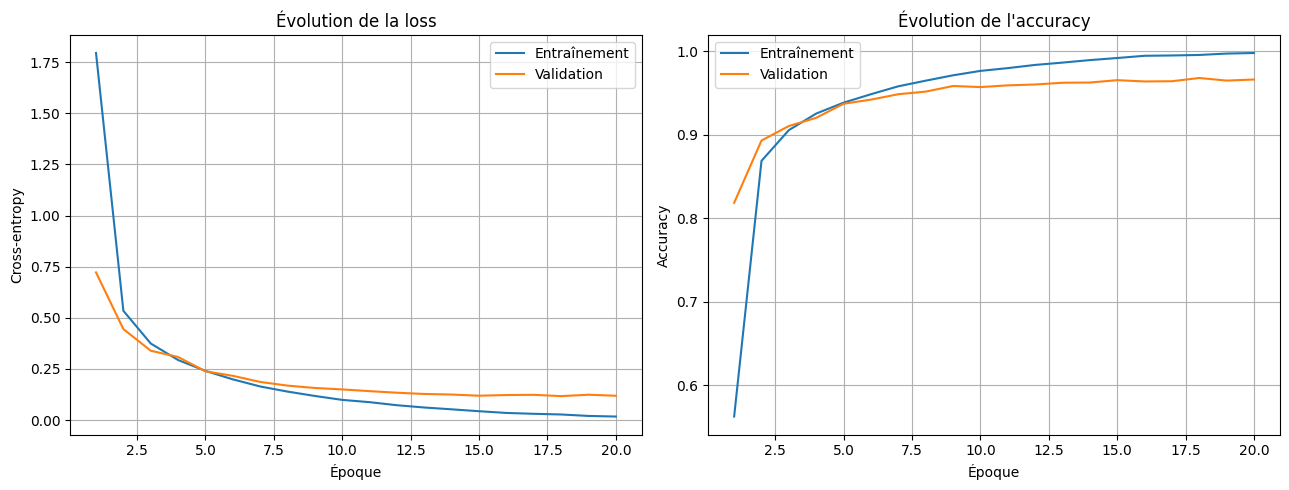

In [11]:
def plot_history(history, filename="courbes_apprentissage.png"):
    h = history.history
    epochs_range = range(1, len(h["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].plot(
        epochs_range,
        h["loss"],
        label="Entraînement"
    )
    axes[0].plot(
        epochs_range,
        h["val_loss"],
        label="Validation"
    )
    axes[0].set_title("Évolution de la loss")
    axes[0].set_xlabel("Époque")
    axes[0].set_ylabel("Cross-entropy")
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(
        epochs_range,
        h["accuracy"],
        label="Entraînement"
    )
    axes[1].plot(
        epochs_range,
        h["val_accuracy"],
        label="Validation"
    )
    axes[1].set_title("Évolution de l'accuracy")
    axes[1].set_xlabel("Époque")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid(True)
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


plot_history(history)

In [12]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

logits = model.predict(test_ds, verbose=1)
y_pred = np.argmax(logits, axis=1)

# y_test a été extrait du dataset dans le même ordre
y_true = np.asarray(y_test)

test_f1_macro = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("\n===== RÉSULTATS SUR LE TEST =====")
print(f"Test loss       : {test_loss:.4f}")
print(f"Test accuracy   : {test_accuracy:.4f}")
print(f"F1 macro        : {test_f1_macro:.4f}")

print("\nRapport de classification :")

print(
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        zero_division=0
    )
)

61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9653 - loss: 0.1311
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step

===== RÉSULTATS SUR LE TEST =====
Test loss       : 0.1311
Test accuracy   : 0.9653
F1 macro        : 0.9654

Rapport de classification :
              precision    recall  f1-score   support

          ya       1.00      1.00      1.00       117
         yab       0.98      0.97      0.97       117
        yach       0.97      0.97      0.97       117
         yad       0.97      0.99      0.98       117
        yadd       0.96      0.94      0.95       117
         yae       0.97      0.99      0.98       117
         yaf       0.96      1.00      0.98       117
         yag       0.95      0.98      0.97       117
        yagh       0.99      0.97      0.98       117
        yagw       0.95      0.95      0.95       117
         yah       0.99      0.95      0.97       117
        yahh       0.98      0.96      0.97       117
         yaj       0.99      0.97      0.98 

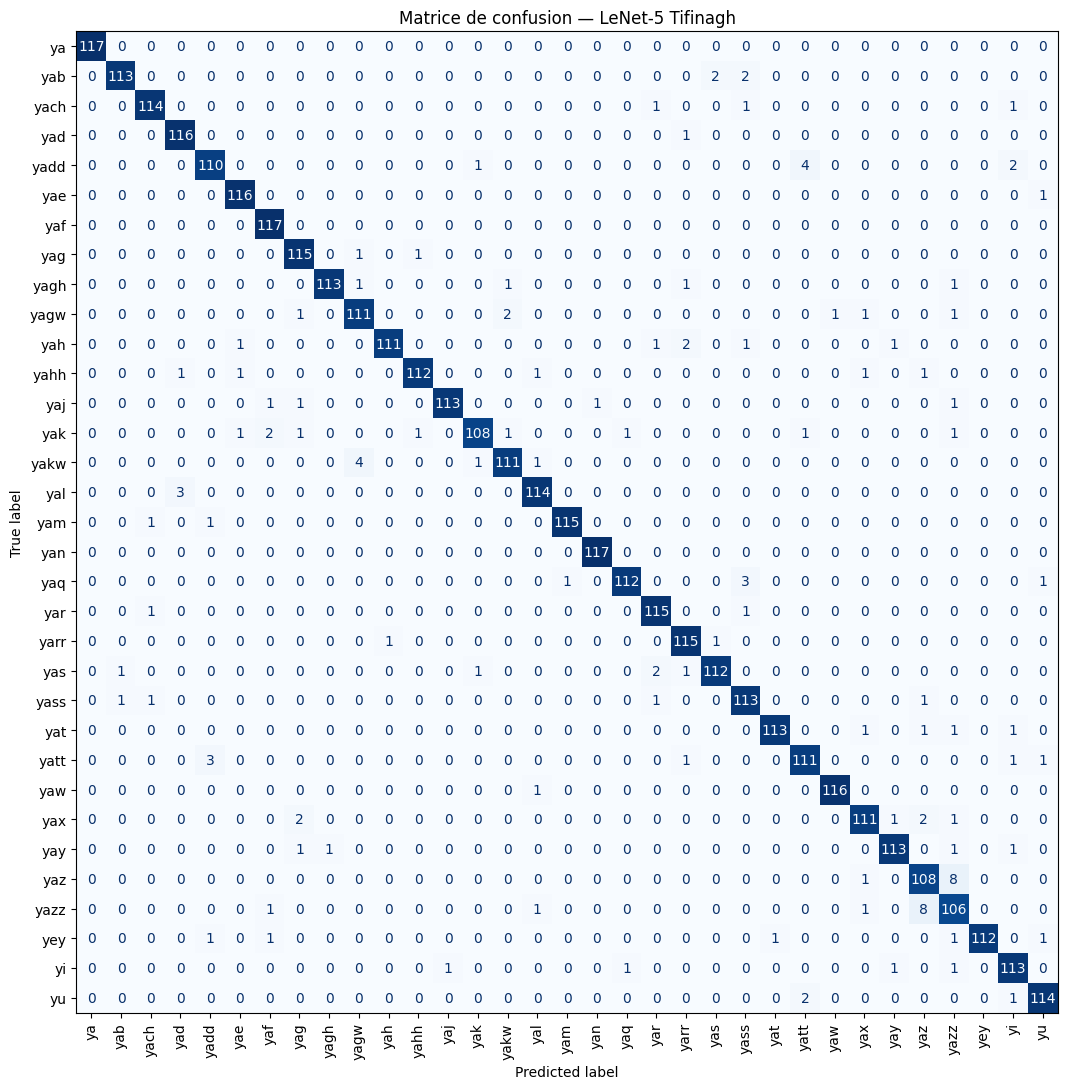

In [13]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(13, 11))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=90,
    colorbar=False
)

plt.title("Matrice de confusion — LeNet-5 Tifinagh")
plt.tight_layout()

plt.savefig(
    "matrice_confusion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

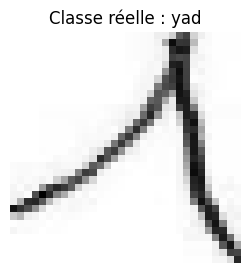

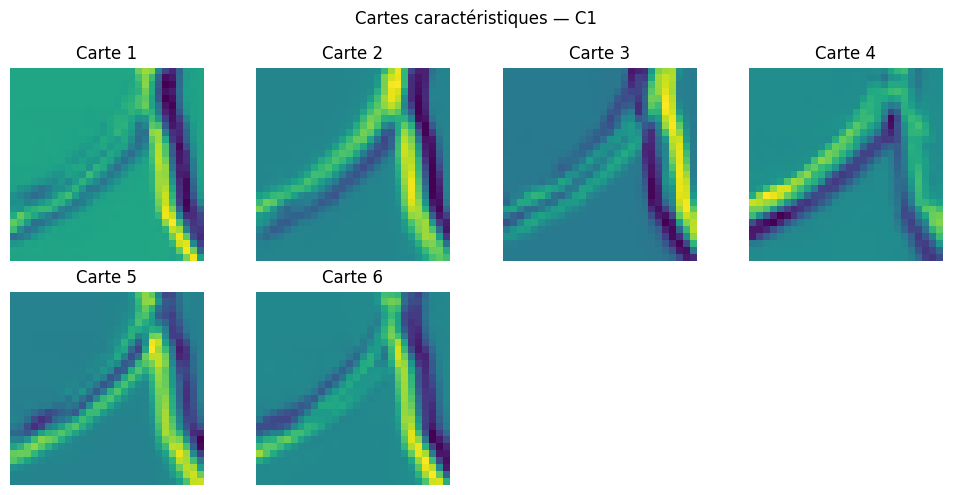

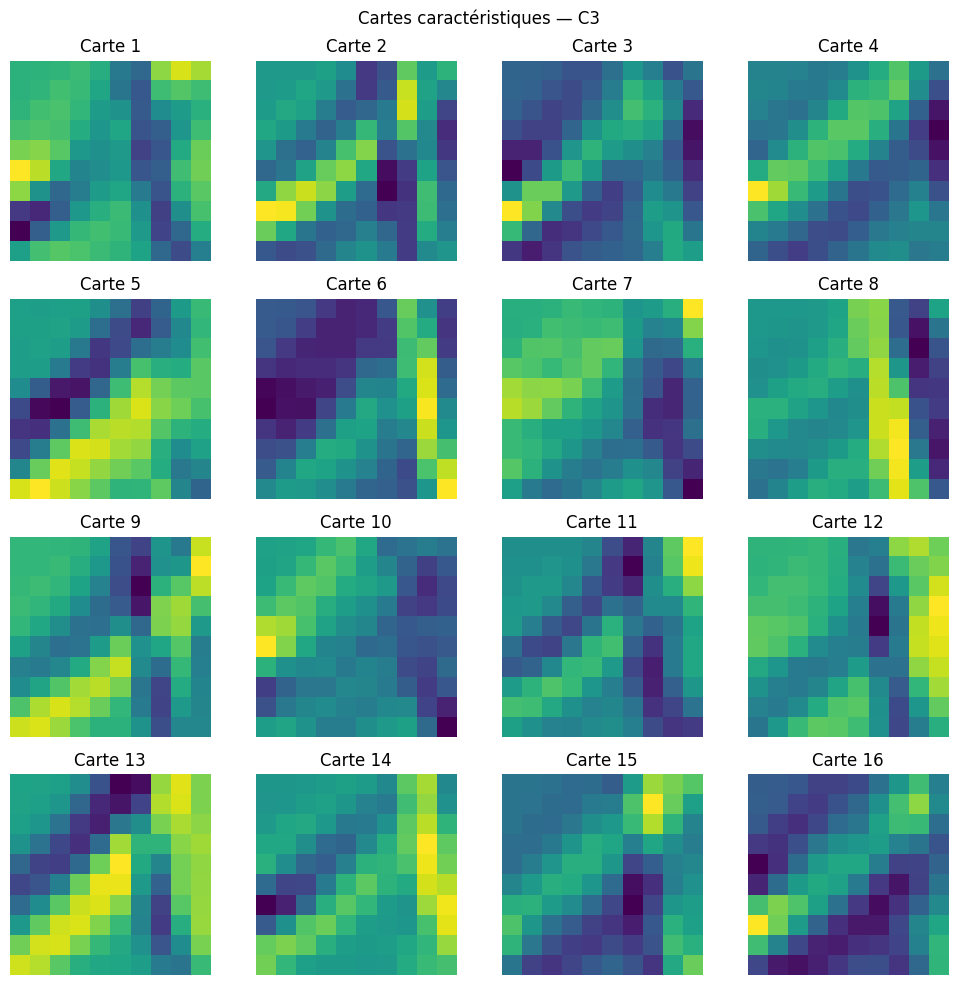

In [14]:
feature_model = tf.keras.Model(
    inputs=model.input,
    outputs=[
        model.get_layer("C1").output,
        model.get_layer("C3").output
    ]
)


def show_feature_maps(feature_maps, title, max_maps=16):
    feature_maps = feature_maps[0]

    n = min(int(feature_maps.shape[-1]), max_maps)
    cols = 4
    rows = int(np.ceil(n / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(10, 2.5 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(
                feature_maps[:, :, i],
                cmap="viridis"
            )
            ax.set_title(f"Carte {i + 1}")

        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


sample_image, sample_label = next(iter(test_ds))
one_image = sample_image[:1]

c1_maps, c3_maps = feature_model.predict(
    one_image,
    verbose=0
)

plt.figure(figsize=(3, 3))
plt.imshow(one_image[0].numpy().squeeze(), cmap="gray")
plt.title(
    "Classe réelle : " +
    class_names[int(sample_label[0].numpy())]
)
plt.axis("off")
plt.show()

show_feature_maps(c1_maps, "Cartes caractéristiques — C1")
show_feature_maps(c3_maps, "Cartes caractéristiques — C3")

In [15]:
def run_experiment(
    optimizer_name,
    learning_rate,
    epochs=20
):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    experiment_model = build_lenet5(
        num_classes=NUM_CLASSES
    )

    history, duration = train_model(
        experiment_model,
        train_ds,
        val_ds,
        epochs=epochs,
        optimizer_name=optimizer_name,
        learning_rate=learning_rate,
        patience=5
    )

    test_loss, test_acc = experiment_model.evaluate(
        test_ds,
        verbose=0
    )

    logits = experiment_model.predict(
        test_ds,
        verbose=0
    )

    predictions = np.argmax(logits, axis=1)

    f1_macro = f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "optimizer": optimizer_name,
        "test_loss": float(test_loss),
        "test_accuracy": float(test_acc),
        "test_f1_macro": float(f1_macro),
        "duration_seconds": float(duration),
        "history": history,
        "model": experiment_model
    }


result_sgd = run_experiment(
    optimizer_name="sgd",
    learning_rate=0.01,
    epochs=EPOCHS
)

result_adam = run_experiment(
    optimizer_name="adam",
    learning_rate=0.001,
    epochs=EPOCHS
)

print("\n===== COMPARAISON DES OPTIMISEURS =====")

for result in [result_sgd, result_adam]:
    print(
        f"{result['optimizer'].upper()} | "
        f"Loss={result['test_loss']:.4f} | "
        f"Accuracy={result['test_accuracy']:.4f} | "
        f"F1 macro={result['test_f1_macro']:.4f} | "
        f"Temps={result['duration_seconds']:.2f}s"
    )


Epoch 1/20


c:\Users\admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.3368 - loss: 2.6682 - val_accuracy: 0.7679 - val_loss: 1.1002
Epoch 2/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8423 - loss: 0.7108 - val_accuracy: 0.8664 - val_loss: 0.5569
Epoch 3/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8982 - loss: 0.4211 - val_accuracy: 0.9140 - val_loss: 0.3469
Epoch 4/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9280 - loss: 0.2985 - val_accuracy: 0.9226 - val_loss: 0.3100
Epoch 5/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9434 - loss: 0.2281 - val_accuracy: 0.9485 - val_loss: 0.2087
Epoch 6/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9560 - loss: 0.1809 - val_accuracy: 0.9560 - val_loss: 0.1710
Epoch 7/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9629 - loss: 0.1471 - val_accuracy: 0.9619 - val_loss: 0.1411
Epoch 8/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.9698 - loss: 0.1219 - val_accuracy: 0.96

c:\Users\admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


282/282 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.5650 - loss: 1.7795 - val_accuracy: 0.8376 - val_loss: 0.7055
Epoch 2/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8720 - loss: 0.5315 - val_accuracy: 0.8920 - val_loss: 0.4307
Epoch 3/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9060 - loss: 0.3751 - val_accuracy: 0.9125 - val_loss: 0.3427
Epoch 4/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9251 - loss: 0.2912 - val_accuracy: 0.9195 - val_loss: 0.2919
Epoch 5/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.9381 - loss: 0.2385 - val_accuracy: 0.9371 - val_loss: 0.2383
Epoch 6/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9494 - loss: 0.1970 - val_accuracy: 0.9409 - val_loss: 0.2144
Epoch 7/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 19s 68ms/step - accuracy: 0.9583 - loss: 0.1626 - val_accuracy: 0.9487 - val_loss: 0.1831
Epoch 8/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 15s 53ms/step - accuracy: 0.9631 - loss: 0.1422 - val_accuracy: 0.9